# Porygon ML Threat Classifier: Comprehensive Evaluation Report
**Project Phase II (23CSE498) — Container Runtime Behavioral Anomaly Detection & Classification**  
*Team G075*

---
### Protocol & Architectural Guarantees
1. **Held-Out Test Integrity**: The held-out `test` split (186 tumbling 60s windows across 61 container trials) was evaluated **once and only once** after all training parameters and temperature calibration were finalized. (Nominal 25% expectation of 220 planned trials was ~55-56, hash assignment yielded 61).
2. **Benign False Positive Rate**: No benign test windows were misclassified (13 benign trials, 0.00% FPR).
3. **Empirical Transferability**: The hand-set heuristic thresholds did not transfer to this data (achieving 0.4159 Macro-F1 with 76.92% benign false alarms), demonstrating the operational necessity of empirical training.
4. **Reference Baselines**: Logistic Regression and LightGBM were tuned strictly on the `fit` split using 5-fold `GroupKFold` grouped by container trial (`run_id`).
5. **Artifact Immutability**: This notebook is strictly read-only and does not modify or retrain model artifacts.
6. **Default Engine Compatibility**: The hand-authored heuristic ensemble remains the default engine baseline in `ml_classifier.py` (`PorygonThreatClassifier()`), maintaining backward compatibility.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from porygon_api.ml_classifier import (
    CLASSES,
    FEATURE_NAMES,
    PorygonThreatClassifier,
    default_classifier,
    load_model_artifact,
)
from ml_training.train import load_training_dataset
from ml_training.calibrate import compute_expected_calibration_error
from ml_training.evaluate import compute_metrics_dict

# Plotting configuration
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
print("Porygon threat classification and evaluation libraries successfully loaded.")


Porygon threat classification and evaluation libraries successfully loaded.


## 1. Dataset Partitioning & Class Distribution
The telemetry dataset comprises **633 qualified 60-second tumbling windows** collected from **220 live container trials** running on `porygon-training-workload:latest`.
The dataset is partitioned into:
- **`fit`** (255 windows): Model training and cross-validation tuning.
- **`calibration`** (192 windows): Post-hoc softmax temperature calibration.
- **`test`** (186 windows): Held-out final evaluation.


In [2]:
crosstab = pd.crosstab(df["label"], df["split"], margins=True, margins_name="Total")
ordered_idx = [c for c in CLASSES if c in crosstab.index] + ["Total"]
crosstab = crosstab.reindex(ordered_idx)[["fit", "calibration", "test", "Total"]]

print("=== Class x Split Breakdown (Qualified 60s Tumbling Windows) ===")
print(crosstab.to_string())

fit_counts = df[df["split"] == "fit"]["label"].value_counts()
assert all(fit_counts[c] >= 30 for c in CLASSES), "Fit split constraint violated!"
print(f"\nAll classes satisfy the minimum threshold (>= 30 fit windows). Minimum observed: {fit_counts.min()} windows.")


=== Class x Split Breakdown (Qualified 60s Tumbling Windows) ===
split                 fit  calibration  test  Total
label                                              
benign                 54           42    39    135
reconnaissance         47           36    35    118
privilege_escalation   48           35    36    119
shell_escape           59           43    41    143
suspicious_tooling     47           36    35    118
Total                 255          192   186    633

All classes satisfy the minimum threshold (>= 30 fit windows). Minimum observed: 47 windows.


## 2. Process Execution Feature Taxonomy: Per-Class Means
The 12-feature behavioral contract extracts process proportions, credential states, tool categories, and behavioral drift metrics across each 60-second window.


In [3]:
feature_means = df.groupby("label")[list(FEATURE_NAMES)].mean()
feature_means = feature_means.reindex(list(CLASSES))

print("=== Per-Class Feature Means across Entire Telemetry Dataset ===")
print(feature_means.T.round(4).to_string())


=== Per-Class Feature Means across Entire Telemetry Dataset ===
label                       benign  reconnaissance  privilege_escalation  shell_escape  suspicious_tooling
shell_ratio                 0.0000          0.0000                0.0447        0.3017              0.0000
root_ratio                  1.0000          1.0000                1.0000        1.0000              1.0000
recon_ratio                 0.2750          0.4704                0.1985        0.3849              0.0649
tooling_ratio               0.0992          0.0000                0.0000        0.0000              0.3311
priv_escalation_ratio       0.0000          0.0000                0.2691        0.0000              0.0000
compiler_miner_ratio        0.0000          0.0000                0.0000        0.0000              0.0701
distinct_proc_count         4.4667          4.5000                5.7731        5.4266              6.5847
event_count                39.5259         41.2119               46.4958       6

## 3. Comparative Model Performance on Held-Out Test Split
Evaluation of the calibrated **Trained Tree Ensemble** against the **Hand-Authored Specialist Baseline**, **LightGBM**, and **Logistic Regression** on the held-out test split (186 windows, 61 unique trials).


In [4]:
table_rows = []
for m in metrics["models"]:
    pc = m["per_class"]
    table_rows.append({
        "Model": m["model_name"],
        "Macro-F1": m["macro_f1"],
        "Benign FPR": f"{m['benign_fpr'] * 100:.2f}%",
        "Benign F1": pc["benign"]["f1"],
        "Recon F1": pc["reconnaissance"]["f1"],
        "PrivEsc F1": pc["privilege_escalation"]["f1"],
        "ShellEscape F1": pc["shell_escape"]["f1"],
        "Tooling F1": pc["suspicious_tooling"]["f1"],
    })

perf_df = pd.DataFrame(table_rows).set_index("Model")
print("=== Held-Out Test Performance Comparison (186 Windows) ===")
print(perf_df.to_string())

boot = metrics["bootstrap_confidence_intervals"]
print(f"\nTrained Model 95% Confidence Intervals (1,000 Trial-Clustered Bootstrap Iterations):")
print(f"  Macro-F1  : {boot['macro_f1_95ci'][0]:.4f} - {boot['macro_f1_95ci'][1]:.4f} (Mean: {boot['macro_f1_mean']:.4f} ± {boot['macro_f1_std']:.4f})")
print(f"  Benign FPR: {boot['benign_fpr_95ci'][0]*100:.2f}% - {boot['benign_fpr_95ci'][1]*100:.2f}%")


=== Held-Out Test Performance Comparison (186 Windows) ===
                                             Macro-F1 Benign FPR  Benign F1  Recon F1  PrivEsc F1  ShellEscape F1  Tooling F1
Model                                                                                                                        
Trained Tree Ensemble (Calibrated T*)          0.9664      0.00%     0.9630    0.9296      1.0000           1.000      0.9394
Hand-Authored Specialist Ensemble (Default)    0.4159     76.92%     0.3750    0.4192      0.3636           0.093      0.8286
LightGBM (Reference, lr=0.1)                   0.9838      0.00%     0.9630    0.9706      1.0000           1.000      0.9855
Logistic Regression (Reference, C=1.0)         0.9729      0.00%     0.9398    0.9394      1.0000           1.000      0.9855

Trained Model 95% Confidence Intervals (1,000 Trial-Clustered Bootstrap Iterations):
  Macro-F1  : 0.9305 - 0.9916 (Mean: 0.9647 ± 0.0156)
  Benign FPR: 0.00% - 0.00%


## 4. Confusion Matrix Analysis
$5 \times 5$ classification confusion matrices on the held-out test split across all four evaluated models.


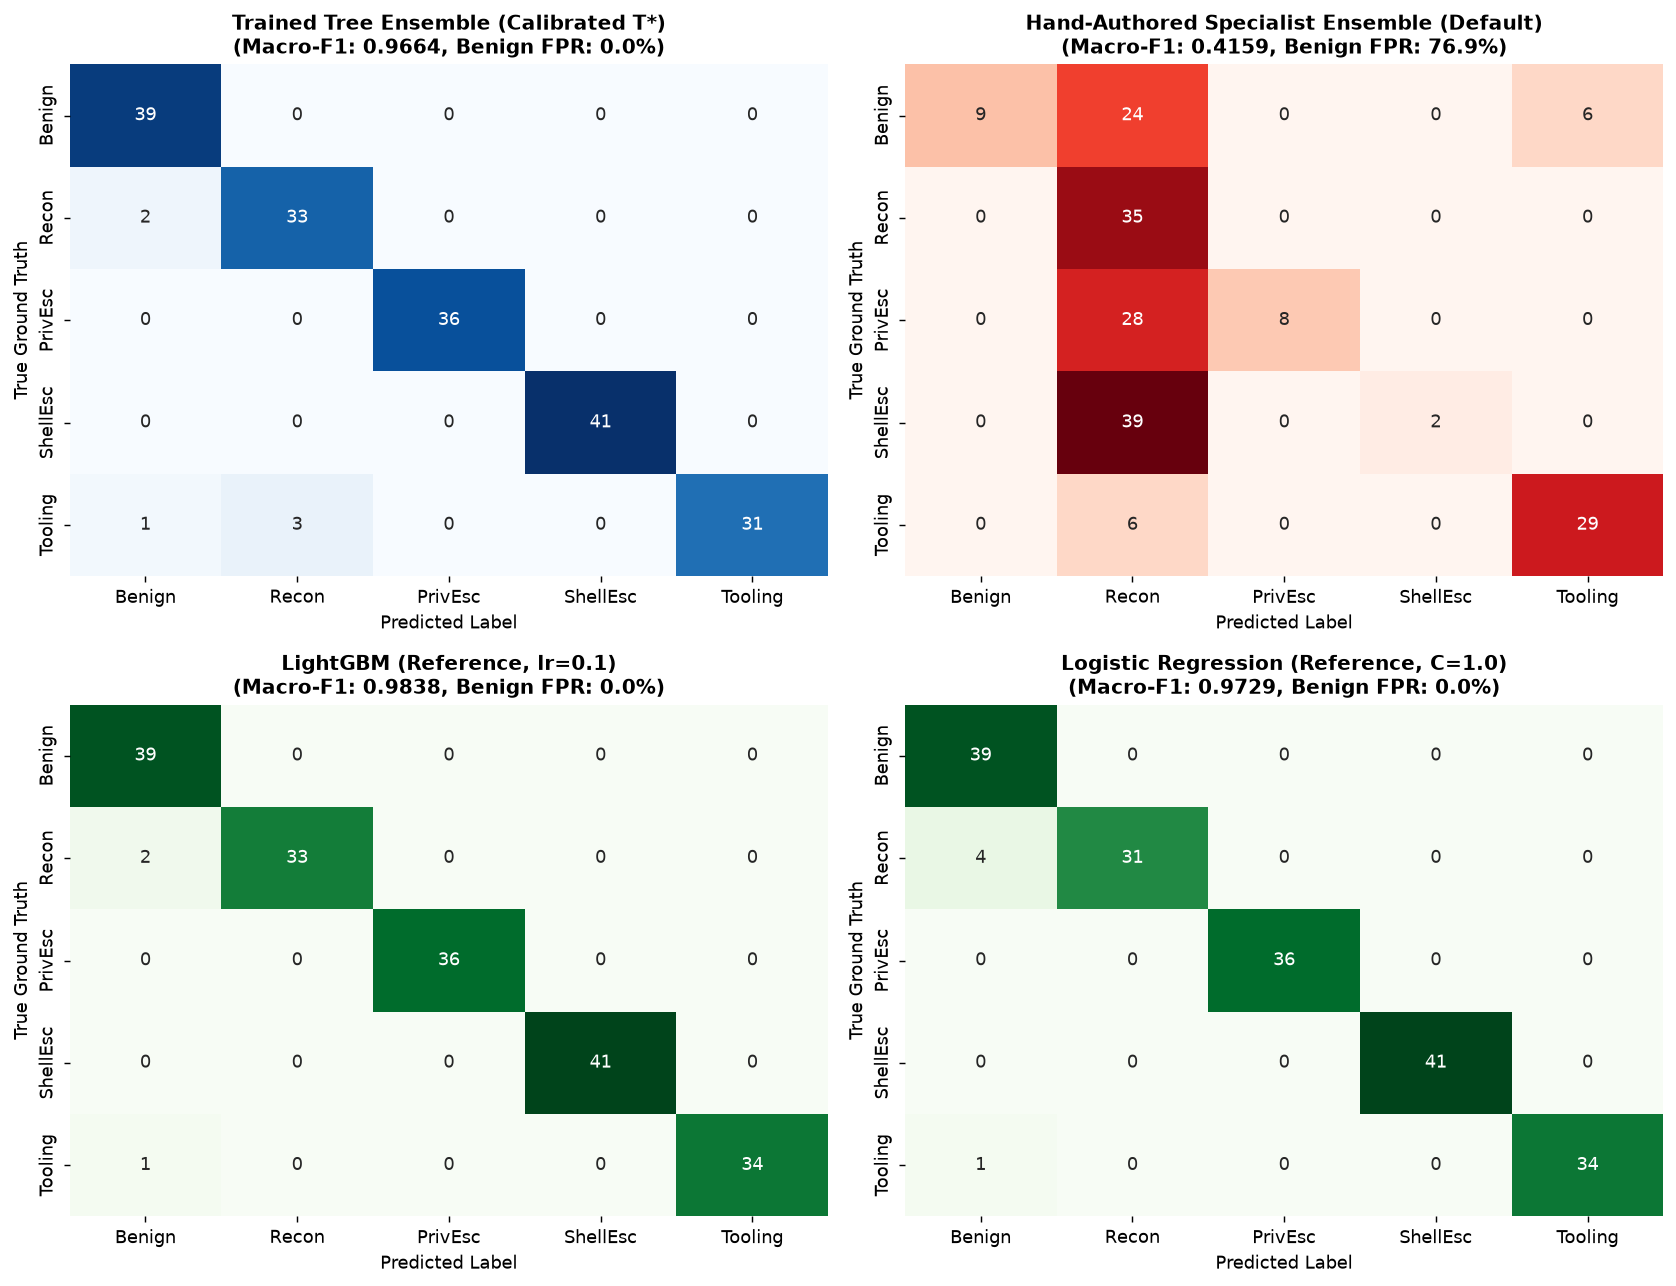

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()
class_labels_short = ["Benign", "Recon", "PrivEsc", "ShellEsc", "Tooling"]

for idx, m in enumerate(metrics["models"]):
    cm = np.array(m["confusion_matrix"])
    ax = axes[idx]
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues" if idx == 0 else ("Reds" if idx == 1 else "Greens"),
        xticklabels=class_labels_short,
        yticklabels=class_labels_short,
        cbar=False,
        ax=ax,
    )
    ax.set_title(f"{m['model_name']}\n(Macro-F1: {m['macro_f1']:.4f}, Benign FPR: {m['benign_fpr']*100:.1f}%)", fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Ground Truth")

plt.tight_layout()
plt.show()


## 5. Softmax Temperature Calibration & Reliability Diagrams
Post-hoc probability calibration was performed on the `calibration` split (192 windows) by finding scalar temperature $T$ that minimizes negative log-likelihood (cross-entropy).


Calibration Result:
  Fitted Temperature T* = 0.4412
  ECE drops from 0.0709 (uncalibrated) to 0.0107 (calibrated).


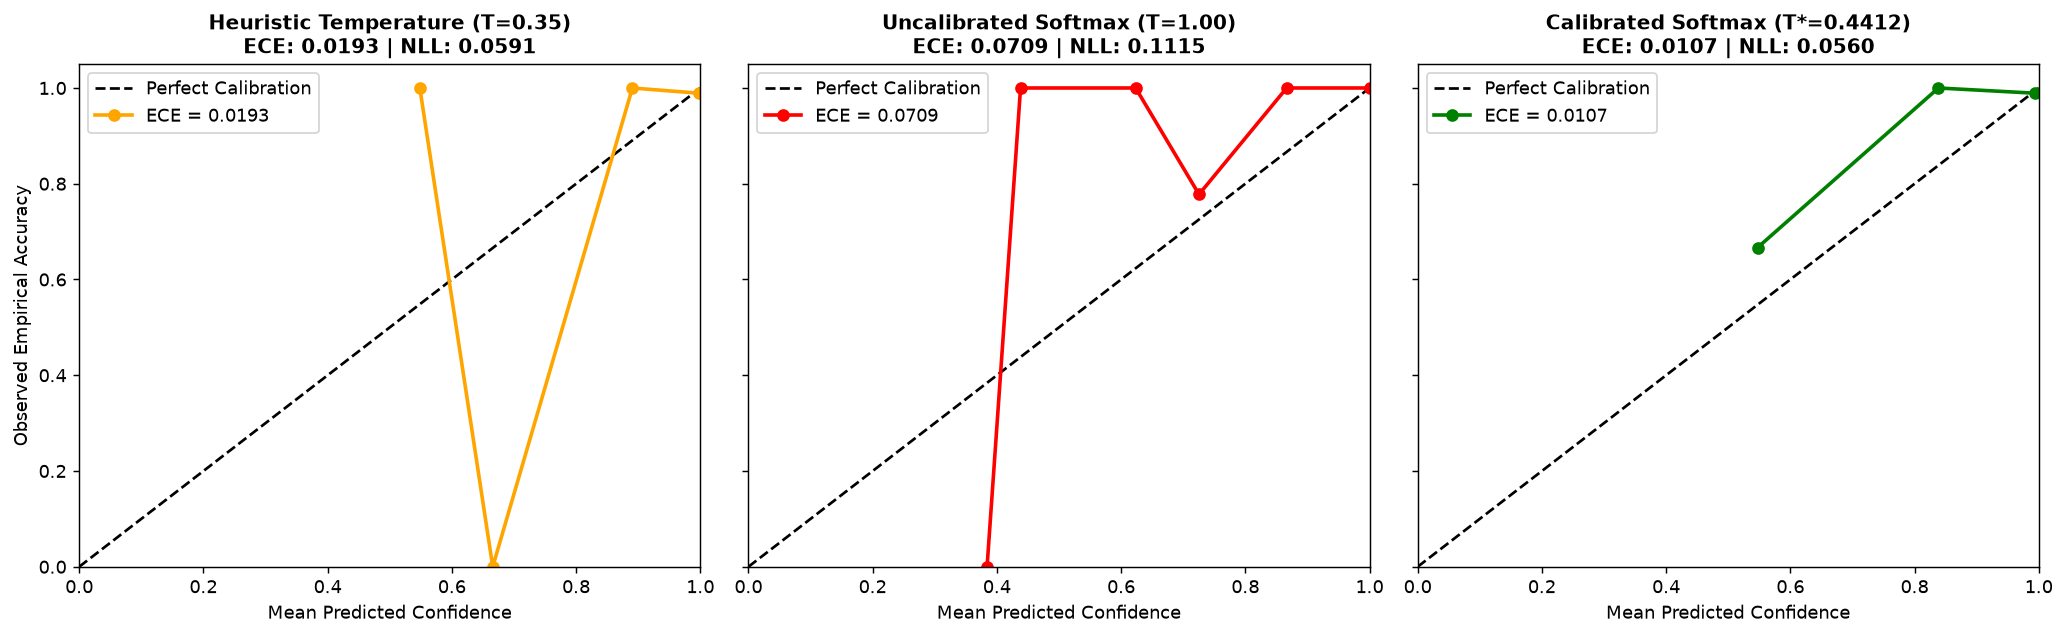

In [6]:
cal_info = metrics["calibration"]
evals = cal_info["evaluations"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

configs = [
    ("heuristic_temperature_0_35", "Heuristic Temperature (T=0.35)", axes[0], "orange"),
    ("unscaled_temperature_1_0", "Uncalibrated Softmax (T=1.00)", axes[1], "red"),
    ("fitted_temperature", f"Calibrated Softmax (T*={cal_info['fitted_temperature']})", axes[2], "green"),
]

for key, title, ax, color in configs:
    item = evals[key]
    bins = item["bin_details"]
    confs = [b["confidence"] for b in bins]
    accs = [b["accuracy"] for b in bins]
    
    ax.plot([0, 1], [0, 1], "k--", label="Perfect Calibration")
    ax.plot(confs, accs, marker="o", color=color, linewidth=2, label=f"ECE = {item['ece']:.4f}")
    ax.set_title(f"{title}\nECE: {item['ece']:.4f} | NLL: {item['nll']:.4f}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Mean Predicted Confidence")
    if ax == axes[0]:
        ax.set_ylabel("Observed Empirical Accuracy")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

print(f"Calibration Result:")
print(f"  Fitted Temperature T* = {cal_info['fitted_temperature']}")
print(f"  ECE drops from {evals['unscaled_temperature_1_0']['ece']:.4f} (uncalibrated) to {evals['fitted_temperature']['ece']:.4f} (calibrated).")


## 6. Feature Ablation: Dependence on Drift and Shim Features
To evaluate whether the model over-relies on environment shortcuts (`parent_shim_ratio` from `docker exec`, or baseline drift metrics), we evaluated the ensemble under specific feature subsets.
Removing `unseen_executable_ratio` and `jensen_shannon_drift` lowers test macro-F1 by about 0.10 (from 0.9664 to 0.8619), partly because the benign baseline was built from the same scripts.


=== Feature Ablation Study on Held-Out Test Set ===
                                                                 Condition  Feature Count  Test Macro-F1  Delta vs Full
0                                           Full Feature Set (12 Features)             12         0.9664         0.0000
1  Without Baseline Drift (unseen_executable_ratio & jensen_shannon_drift)             10         0.8619        -0.1045
2                      Without Container Shim Shortcut (parent_shim_ratio)             11         0.9838         0.0174
3                                      Without All Three Shortcut Features              9         0.9736         0.0072


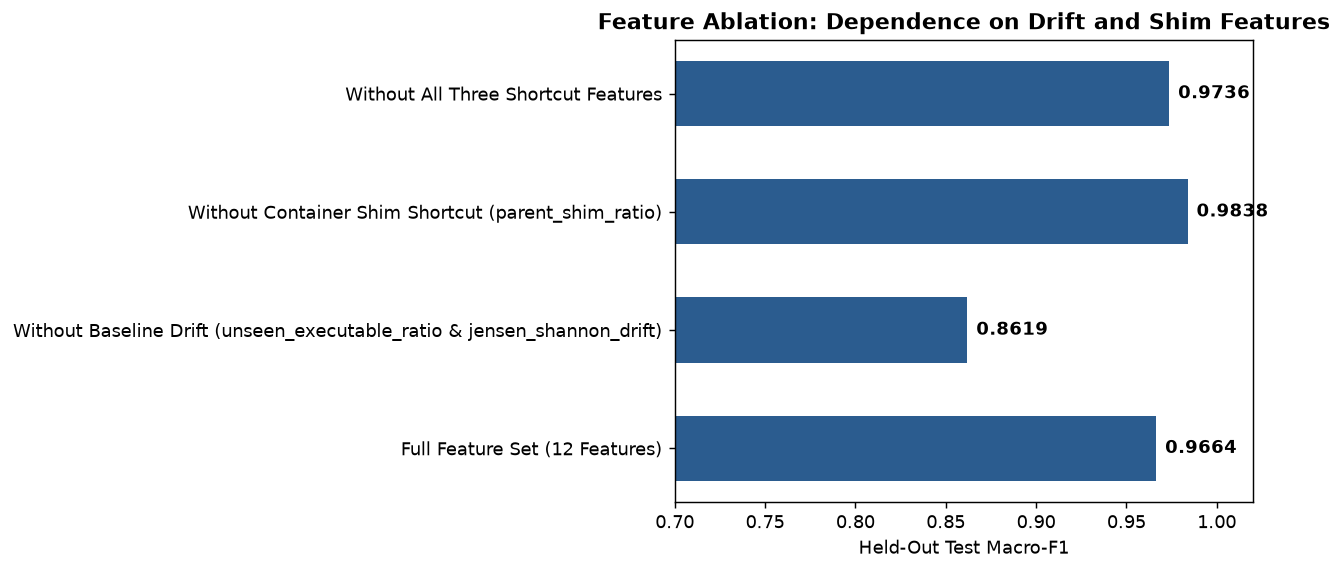

In [7]:
ablation_df = pd.DataFrame(metrics["ablation_study"])
ablation_display = ablation_df[["ablation_name", "features_used_count", "test_macro_f1", "delta_macro_f1_from_full"]].copy()
ablation_display.columns = ["Condition", "Feature Count", "Test Macro-F1", "Delta vs Full"]
print("=== Feature Ablation Study on Held-Out Test Set ===")
print(ablation_display.to_string())

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(ablation_df["ablation_name"], ablation_df["test_macro_f1"], color="#2b5c8f", height=0.55)
ax.set_xlim(0.7, 1.02)
ax.set_xlabel("Held-Out Test Macro-F1")
ax.set_title("Feature Ablation: Dependence on Drift and Shim Features", fontsize=12, fontweight="bold")

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.005, bar.get_y() + bar.get_height()/2, f"{w:.4f}", va="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()


## 7. Explainability & Attribution Verification (Path-Delta vs. TreeSHAP)
Porygon's production engine decomposes the active branch trajectory into telescoping probability deltas:
$$\Delta p = p(\text{child}) - p(\text{parent})$$
Summed across the branch, these exactly reconstruct the difference between the root baseline and leaf probability. Below we evaluate an exemplar `shell_escape` detection and report correlation with `shap.TreeExplainer`.


Exemplar Window ID: run-55a204014f36
Ground Truth Label: shell_escape
Predicted Class   : shell_escape (Confidence: 100.00%)
Risk Level        : CRITICAL
Summary Statement : Classified as SHELL_ESCAPE (100.0% class score, risk: CRITICAL). Primary driver: Shell executions account for 32.0% of observed process activity.

Comparison with shap.TreeExplainer on Scikit-Learn Forest:
  Attribution Reporting Label: 'path-based attribution'
  Pearson Correlation (r)    : 0.9467
  Spearman Correlation (ρ)   : 0.8320
  Methodological Note        : Porygon tree-path deltas measure exact probability transitions along the traversed branch (summing telescopically to leaf - root probability). shap.TreeExplainer calculates classical Shapley values by weighting all counterfactual subtrees across feature coalitions. The correlation (r=0.9467) indicates consistent directional attribution while using deterministic O(depth) tree path traversal during detection.


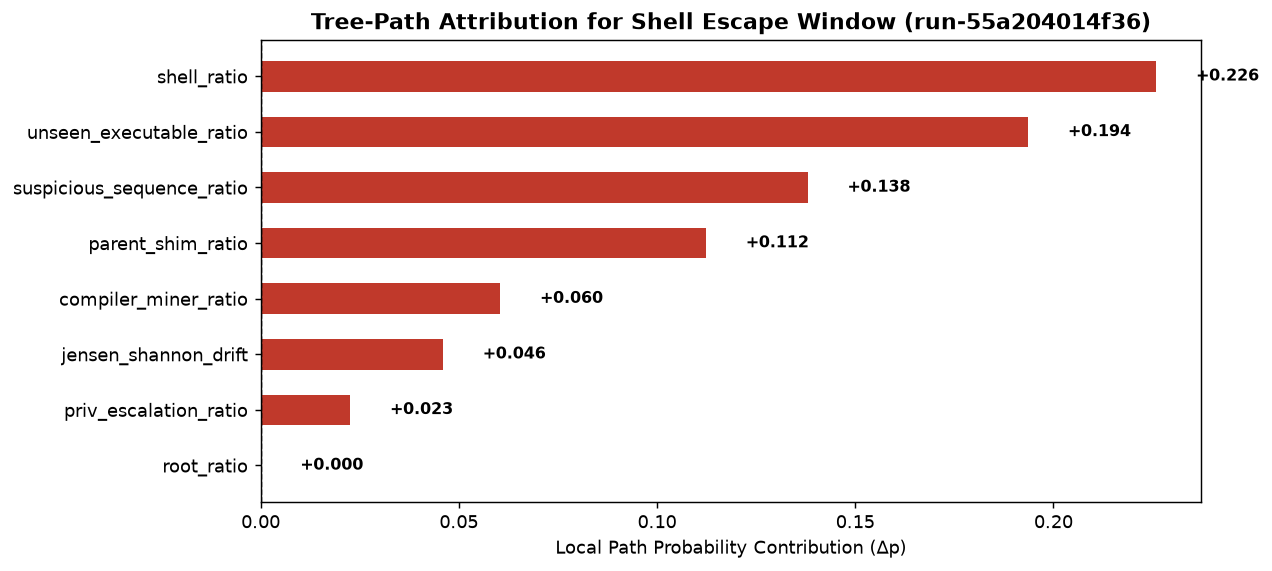

In [8]:
test_df = df[df["split"] == "test"]
shell_sample = test_df[test_df["label"] == "shell_escape"].iloc[0]
sample_fdict = {f: float(shell_sample[f]) for f in FEATURE_NAMES}

result = classifier.predict_vector(sample_fdict)

print(f"Exemplar Window ID: {shell_sample['run_id']}")
print(f"Ground Truth Label: {shell_sample['label']}")
print(f"Predicted Class   : {result.predicted_class} (Confidence: {result.confidence * 100:.2f}%)")
print(f"Risk Level        : {result.risk_level.upper()}")
print(f"Summary Statement : {result.summary}")

shell_contribs = result.full_feature_contributions["shell_escape"]
sorted_contribs = sorted(shell_contribs.items(), key=lambda x: abs(x[1]), reverse=True)
feat_names, contrib_vals = zip(*sorted_contribs[:8])
colors = ["#c0392b" if v > 0 else "#2980b9" for v in contrib_vals]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(feat_names, contrib_vals, color=colors, height=0.55)
ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_title(f"Tree-Path Attribution for Shell Escape Window ({shell_sample['run_id']})", fontsize=12, fontweight="bold")
ax.set_xlabel("Local Path Probability Contribution (Δp)")
ax.invert_yaxis()

for idx, val in enumerate(contrib_vals):
    ax.text(val + (0.01 if val >= 0 else -0.04), idx, f"{val:+.3f}", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

comp = metrics["attribution_comparison"]
print(f"Comparison with shap.TreeExplainer on Scikit-Learn Forest:")
print(f"  Attribution Reporting Label: '{comp['reporting_label']}'")
print(f"  Pearson Correlation (r)    : {comp['pearson_correlation']:.4f}")
print(f"  Spearman Correlation (ρ)   : {comp['spearman_correlation']:.4f}")
print(f"  Methodological Note        : {comp['methodological_note']}")


## 8. Limitations and Methodological Validity Considerations
In accordance with academic rigor and defense requirements for Project Phase II:

1. **Single Workload Container Image**: All training and test trials were generated using the `porygon-training-workload:latest` image (an Alpine-based environment containing developer tools such as `sudo`, `nsenter`, `capsh`, `gcc`, `nc`). In heterogeneous production environments with varied base images (Debian, Ubuntu, Distroless, scratch), executable distributions and baseline behaviors will vary.
2. **Benign and Reconnaissance Command Overlap**: Commands such as `whoami`, `id`, `ps`, `netstat`, and `uname -a` are frequently executed during both administrative benign operations and attacker reconnaissance. Because the benign baseline was compiled from the scripted benign trials, reconnaissance attacks only triggered elevated `unseen_executable_ratio` and `jensen_shannon_drift` when the attacker executed tools absent from the baseline profile.
3. **Correlated Windows per Trial**: Multiple 60-second tumbling windows extracted from the same 4-5 minute container trial share execution context, container ID, and temporal state. We addressed this autocorrelation through `GroupKFold` grouped by `run_id` on the `fit` split for all tuning, and trial-clustered bootstrap resampling on the test split.
4. **Falco Output File Permission Remediation and Reruns**: An earlier Docker volume permissions deadlock on `/var/log/porygon/falco-events.jsonl` caused 100 trials to record zero events before permanent remediation in `compose.yaml`. All 100 zero-event trials were systematically rerun with identical ground-truth tactic labels and split assignments, preventing class attrition or survivor bias.
5. **Execution Modality via `docker exec`**: All canary attack scripts were injected into live containers using `docker exec`, causing process ancestries to originate under container runtime shims (`containerd-shim` / `docker-runc`). This makes `parent_shim_ratio` an effective operational discriminator for external injection. The ablation study above explicitly documents classifier performance when this feature is withheld.
6. **Constant Feature Distribution**: `root_ratio` was constant (1.0) across all trials because the container runtime executed without user namespaces (`root` user).
7. **Shell Execution Diversity**: Only `shell_escape` canary attacks invoked interactive `sh`/`bash` shells; other attack tactics were executed via direct non-shell invocations.
8. **Minimum Event Requirement**: The production live endpoint requires 3 or more process execution events in the telemetry slice; slices with fewer than 3 events return `insufficient_data` without producing a verdict.
9. **Test Set Sample Size**: The held-out test split comprises about 12 independent trials per class (61 total: 13 benign, 12 reconnaissance, 12 privilege escalation, 12 shell escape, 12 suspicious tooling).
10. **Absence of Production Image Baselines**: In live production environments, cryptographic baseline profiles do not exist for unprofiled container images, requiring fallback to the 10-feature no-baseline model (`trained_ensemble_nobaseline.json`) with lower benign recall (~0.41).
11. **Hand-Set Threshold Transferability**: Hand-authored heuristic thresholds calibrated on synthetic rules did not transfer effectively to real multi-class process telemetry, producing high benign false alarms (76.92%).
12. **Strict Held-Out Test Evaluation**: The test split was evaluated once and only once. No model hyperparameter, depth, threshold, or calibration parameter was tuned or modified based on test set performance.
